# 🏎️ تحليل بيانات Formula 1 — المرحلة 1 و 2
**المرحلة 1:** إعداد البيئة + قراءة الملفات بكفاءة + فحص الجداول والمفاتيح  
**المرحلة 2:** تنظيف البيانات + توحيد الصيغ + التحقق من سلامة العلاقات + حفظ نسخة نظيفة (Parquet)

> شغّل الخلايا بالترتيب. مخرجات المرحلة 2 تُحفظ في `/content/f1_clean` وتُستخدم في المرحلتين 3 و 4.

## 🔧 المرحلة 1 — الإعداد والفحص
### 1.1 الاستيراد ورفع/فك ضغط الأرشيف

In [1]:
import os, re, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.float_format", "{:,.3f}".format)

try:
    from IPython.display import display
except ImportError:          # لو شغّلته كسكربت عادي
    display = print

# ---- هل نحن داخل Colab؟ ----
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE      = Path("/content") if IN_COLAB else Path(os.environ.get("F1_WORKDIR", "/tmp/f1"))
RAW_DIR   = BASE / "f1_raw"      # CSV الخام بعد فك الضغط
CLEAN_DIR = BASE / "f1_clean"    # مخرجات التنظيف
RAW_DIR.mkdir(parents=True, exist_ok=True); CLEAN_DIR.mkdir(parents=True, exist_ok=True)

# ---- رفع الـ ZIP (Colab) أو أخذ المسار من متغير بيئة (محلياً) ----
if IN_COLAB:
    print("⬆️ اختر ملف الـ ZIP...")
    uploaded = files.upload()                       # بديل: from google.colab import drive; drive.mount('/content/drive')
    ZIP_PATH = BASE / next(iter(uploaded))
else:
    ZIP_PATH = Path(os.environ["ZIP_PATH"])

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(RAW_DIR)

# نجمع كل ملفات CSV (حتى لو كانت داخل مجلد فرعي في الأرشيف)
CSV_PATHS = {p.stem: p for p in RAW_DIR.rglob("*.csv") if not p.name.startswith("._")}
print(f"✅ تم العثور على {len(CSV_PATHS)} ملف:", sorted(CSV_PATHS))
assert len(CSV_PATHS) == 15, "عدد الملفات غير 15 — راجع محتوى الأرشيف"

⬆️ اختر ملف الـ ZIP...


Saving archive.zip to archive.zip
✅ تم العثور على 15 ملف: ['circuits', 'constructor_results', 'constructor_standings', 'constructors', 'driver_standings', 'drivers', 'lap_times', 'pit_stops', 'practice_sessions', 'qualifying', 'races', 'results', 'seasons', 'sprint_results', 'status']


### 1.2 قراءة الجداول بكفاءة (تحديد `dtypes` مسبقاً)
- **القيم الفارغة:** نمرّر `na_values` صريحة (`\N` و`?` والفراغات) مع `keep_default_na=False` حتى لا يتحول نص مثل `"NA"` لقيمة مفقودة بالخطأ.
- **أنواع الأعمدة:** `int16/int8` للمفاتيح والأرقام الصغيرة، و`Int*` (nullable) للأعمدة التي بها NaN، و`category` للنصوص المتكررة.
- **`lap_times`:** هو الجدول الأضخم (~639 ألف صف). المفاتيح تصبح `int16` فينخفض استهلاك الذاكرة بشدة.

In [2]:
NA_TOKENS = ["", " ", "\\N", "?", "N/A", "NULL", "null", "nan", "NaN"]

# اختصارات
I8, I16, I32 = "Int8", "Int16", "Int32"     # nullable (تقبل NaN)
i8, i16, i32 = "int8", "int16", "int32"     # عادية (بدون NaN)
S, C, F32, F64 = "string", "category", "float32", "float64"

SCHEMA = {
 "circuits":  dict(circuitId=i16, circuitRef=S, name=S, location=S, country=C, lat=F64, lng=F64, alt=I16, url=S),
 "constructors": dict(constructorId=i16, constructorRef=S, name=S, nationality=C, url=S),
 "drivers":   dict(driverId=i16, driverRef=S, number=I16, code=S, forename=S, surname=S, dob=S, nationality=C, url=S),
 "seasons":   dict(year=i16, url=S),
 "status":    dict(statusId=i16, status=S),
 "races":     dict(raceId=i16, year=i16, round=i8, circuitId=i16, name=S, date=S, time=S, url=S,
                   fp1_date=S, fp1_time=S, fp2_date=S, fp2_time=S, fp3_date=S, fp3_time=S,
                   quali_date=S, quali_time=S, sprint_date=S, sprint_time=S),
 "results":   dict(resultId=i32, raceId=i16, driverId=i16, constructorId=i16, number=I16, grid=i16, position=I8,
                   positionText=C, positionOrder=i8, points=F64, laps=i16, time=S, milliseconds=I32,
                   fastestLap=I16, rank=I8, fastestLapTime=S, fastestLapSpeed=F32, statusId=i16),
 "sprint_results": dict(resultId=i32, raceId=i16, driverId=i16, constructorId=i16, number=I16, grid=i16, position=I8,
                   positionText=C, positionOrder=i8, points=F32, laps=i16, time=S, milliseconds=I32,
                   fastestLap=I16, fastestLapTime=S, statusId=i16),
 "qualifying": dict(qualifyId=i32, raceId=i16, driverId=i16, constructorId=i16, number=I16, position=I8,
                    q1=S, q2=S, q3=S),
 "lap_times": dict(raceId=i16, driverId=i16, lap=i16, position=I8, time=S, milliseconds=i32),
 "pit_stops": dict(raceId=i16, driverId=i16, stop=i8, lap=i16, time=S, duration=S, milliseconds=i32),
 "practice_sessions": dict(raceId=i16, driverId=i16, constructorId=i16, session=C, position=i8,
                           time=S, milliseconds=I32, laps=i16),
 "driver_standings": dict(driverStandingsId=i32, raceId=i16, driverId=i16, points=F64, position=I16,
                          positionText=C, wins=i8),
 "constructor_standings": dict(constructorStandingsId=i32, raceId=i16, constructorId=i16, points=F64,
                               position=I16, positionText=C, wins=i8),
 "constructor_results": dict(constructorResultsId=i32, raceId=i16, constructorId=i16, points=F64, status=C),
}

def load_table(name):
    return pd.read_csv(CSV_PATHS[name], dtype=SCHEMA[name], na_values=NA_TOKENS, keep_default_na=False)

raw = {name: load_table(name) for name in SCHEMA}
missing_files = set(SCHEMA) - set(CSV_PATHS)
assert not missing_files, f"ملفات ناقصة: {missing_files}"
print("✅ تمت قراءة", len(raw), "جدول")

✅ تمت قراءة 15 جدول


### 1.3 استهلاك الذاكرة وحجم كل جدول

In [3]:
def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

# مقارنة سريعة لـ lap_times: القراءة الافتراضية مقابل المُحسّنة
naive = pd.read_csv(CSV_PATHS["lap_times"])
print(f"lap_times  | افتراضي: {mem_mb(naive):6.1f} MB   |  مُحسّن: {mem_mb(raw['lap_times']):6.1f} MB")
del naive

overview = pd.DataFrame({
    "rows": {k: len(v) for k, v in raw.items()},
    "cols": {k: v.shape[1] for k, v in raw.items()},
    "mem_MB": {k: round(mem_mb(v), 2) for k, v in raw.items()},
    "file_MB": {k: round(CSV_PATHS[k].stat().st_size / 1024**2, 2) for k in raw},
}).sort_values("rows", ascending=False)
display(overview)

lap_times  | افتراضي:   59.1 MB   |  مُحسّن:   42.1 MB


,rows,cols,mem_MB,file_MB
lap_times,639293,6,42.070,17.630
driver_standings,35072,7,0.710,0.780
results,26313,18,3.960,1.350
constructor_standings,13701,7,0.280,0.300
pit_stops,13029,7,1.530,0.440
constructor_results,12565,5,0.200,0.190
qualifying,11410,9,2.010,0.440
practice_sessions,2051,8,0.140,0.070
races,1169,18,0.960,0.150
drivers,835,9,0.310,0.070


### 1.4 فحص الجودة: القيم المفقودة والتكرارات والرموز الشاذة
- نفحص الملفات الخام نصياً بحثاً عن `\N` و`?` (قبل التحويل لـ NaN)، ثم نُلخّص المفقود في كل جدول.

In [4]:
# ---- (أ) رموز غير قياسية في الملفات الخام ----
tok_rows = []
for name, path in CSV_PATHS.items():
    txt = path.read_text(encoding="utf-8", errors="replace")
    tok_rows.append(dict(table=name, backslash_N=txt.count("\\N"), question_mark_cells=len(re.findall(r"(?:^|,)\?(?:,|$)", txt, re.M))))
tokens = pd.DataFrame(tok_rows).set_index("table")
print("رموز \\N / ? في الملفات الخام (إجمالي كل الجداول):", int(tokens.sum().sum()), "-> الفراغات الحقيقية هي الممثلة للقيم المفقودة" if tokens.sum().sum() == 0 else "-> سيتم تحويلها لـ NaN عند القراءة")
if tokens.sum().sum(): display(tokens[(tokens > 0).any(axis=1)])

# ---- (ب) المفقود والتكرار لكل جدول ----
def profile(name, df):
    na = df.isna().sum(); na = na[na > 0]
    return dict(table=name, rows=len(df), cols=df.shape[1],
                exact_duplicates=int(df.duplicated().sum()),
                cols_with_na=len(na),
                na_detail="; ".join(f"{c}={n} ({n/len(df):.0%})" for c, n in na.items()) or "—")

profile_df = pd.DataFrame([profile(n, d) for n, d in raw.items()]).set_index("table")
with pd.option_context("display.max_colwidth", 140):
    display(profile_df)

رموز \N / ? في الملفات الخام (إجمالي كل الجداول): 0 -> الفراغات الحقيقية هي الممثلة للقيم المفقودة


,rows,cols,exact_duplicates,cols_with_na,na_detail
table,,,,,
circuits,78,9,0,0,—
constructors,205,5,0,0,—
drivers,835,9,0,5,number=771 (92%); code=727 (87%); dob=16 (2%); nationality=16 (2%); url=16 (2%)
seasons,77,2,0,0,—
status,136,2,0,0,—
races,1169,18,0,10,time=731 (63%); fp1_date=750 (64%); fp1_time=1057 (90%); fp2_date=774 (66%); fp2_time=1081 (92%); fp3_date=780 (67%); fp3_time=1084 (93%...
results,26313,18,0,8,number=6 (0%); position=9719 (37%); time=17662 (67%); milliseconds=17626 (67%); fastestLap=17162 (65%); rank=17138 (65%); fastestLapTime...
sprint_results,612,16,0,5,position=45 (7%); time=49 (8%); milliseconds=46 (8%); fastestLap=23 (4%); fastestLapTime=23 (4%)
qualifying,11410,9,0,4,position=4 (0%); q1=195 (2%); q2=5023 (44%); q3=7365 (65%)


### 1.5 المفاتيح الأساسية (PK) والخارجية (FK)

In [5]:
# المفتاح الأساسي لكل جدول (الجداول التفصيلية لها مفتاح مركّب)
PK = {
 "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
 "seasons": ["year"], "status": ["statusId"], "races": ["raceId"],
 "results": ["resultId"], "sprint_results": ["resultId"], "qualifying": ["qualifyId"],
 "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
 "constructor_results": ["constructorResultsId"],
 "lap_times": ["raceId", "driverId", "lap"],
 "pit_stops": ["raceId", "driverId", "stop"],
 "practice_sessions": ["raceId", "driverId", "session"],
}
# (جدول_الابن, عمود, جدول_الأب)
FK = [(t, "raceId", "races") for t in ["results","sprint_results","qualifying","pit_stops","lap_times",
                                      "driver_standings","constructor_standings","constructor_results","practice_sessions"]] \
   + [(t, "driverId", "drivers") for t in ["results","sprint_results","qualifying","pit_stops","lap_times",
                                          "driver_standings","practice_sessions"]] \
   + [(t, "constructorId", "constructors") for t in ["results","sprint_results","qualifying",
                                                    "constructor_standings","constructor_results","practice_sessions"]] \
   + [("races","circuitId","circuits"), ("races","year","seasons"),
      ("results","statusId","status"), ("sprint_results","statusId","status")]

def check_pk(tables):
    rows = []
    for t, cols in PK.items():
        df = tables[t]
        rows.append(dict(table=t, pk=",".join(cols), null_in_pk=int(df[cols].isna().any(axis=1).sum()),
                         duplicate_keys=int(df.duplicated(cols).sum())))
    return pd.DataFrame(rows).set_index("table")

def check_fk(tables):
    rows = []
    for child, col, parent in FK:
        orphan = ~tables[child][col].isin(tables[parent][col])
        rows.append(dict(child=child, column=col, parent=parent, orphan_rows=int(orphan.sum())))
    return pd.DataFrame(rows)

pk_report = check_pk(raw); fk_report = check_fk(raw)
display(pk_report[pk_report.duplicate_keys + pk_report.null_in_pk > 0])
print("FK بها صفوف يتيمة (Orphans):", int((fk_report.orphan_rows > 0).sum()), "من", len(fk_report))

,pk,null_in_pk,duplicate_keys
table,,,


FK بها صفوف يتيمة (Orphans): 0 من 26


In [6]:
# فحص (raceId, driverId) في results: هل هو فريد؟ (نتوقع تكرارات تاريخية = "سائق مشترك في سيارتين")
res = raw["results"]
dups = res[res.duplicated(["raceId", "driverId"], keep=False)].merge(raw["races"][["raceId", "year"]], on="raceId")
print(f"صفوف (raceId, driverId) المكررة في results: {len(dups)}")
print("توزيعها حسب السنة:", dups.year.value_counts().sort_index().to_dict())
display(dups.sort_values(["raceId", "driverId"]).head(6)[["resultId","raceId","driverId","constructorId","grid","positionOrder","points"]])

صفوف (raceId, driverId) المكررة في results: 172
توزيعها حسب السنة: {1950: 8, 1951: 8, 1952: 6, 1953: 30, 1954: 33, 1955: 33, 1956: 24, 1957: 16, 1958: 4, 1960: 2, 1961: 4, 1962: 2, 1964: 2}


,resultId,raceId,driverId,constructorId,grid,positionOrder,points
0,49,3,38,10,9,5,1.000
1,77,3,38,11,8,31,0.000
2,118,6,5,5,15,6,0.000
3,125,6,5,5,6,12,0.000
5,145,7,13,1,7,13,0.000
6,148,7,13,1,1,15,1.000


### 📌 خلاصة المرحلة 1 (من البيانات الفعلية)
| ملاحظة | التفاصيل | القرار |
|---|---|---|
| حجم الذاكرة | `lap_times` ≈ 639k صف (34 MB بالقراءة الافتراضية) | تقليل الأنواع + حذف عمود `time` النصي بعد التحقق منه (→ ~10 MB) |
| القيم المفقودة | معظمها **طبيعي** (مثلاً `fp1_date` للمواسم القديمة، `q2/q3` لمن لم يتأهل، `position` للمنسحبين) | **لا نملؤها بقيمة وهمية**؛ نُبقيها NaN ونضيف أعمدة Flags |
| الصفوف الفريدة | لا تكرارات كاملة (Exact duplicates) | لا حذف |
| تكرار `(raceId, driverId)` في `results` | 89 تكراراً (172 صفاً بالأزواج) بين 1950–1964 — **قيادة مشتركة أو تبديل سيارة** (مشروع ولا يُحذف) | نستخدم `resultId` كمفتاح، ونضيف `is_shared_drive` |
| العلاقات | لا Orphans في أي FK | سليمة ✅ |
| `pit_stops.duration` | بعض القيم بصيغة `16:44.718` (دقائق) وقيم > 120 ث | نعتمد `milliseconds` ونضيف Flag للشواذ |

## 🧹 المرحلة 2 — تنظيف البيانات
### 2.1 دوال مساعدة (تحويل الأزمنة + تنظيف النصوص)

In [8]:
clean = {k: v.copy() for k, v in raw.items()}      # نعمل على نسخة ونُبقي raw كما هي

# ---------- (1) توحيد النصوص: إزالة المسافات الزائدة ----------
def strip_strings(df):
    for c in df.columns:
        if pd.api.types.is_string_dtype(df[c]) and df[c].dtype != "category":
            df[c] = df[c].str.strip().replace("", pd.NA)
    return df

for k in clean: clean[k] = strip_strings(clean[k])

# ---------- (2) تحويل أي زمن نصي إلى ميلي ثانية ----------
# يدعم:  "56.481"  |  "1:56.481"  |  "1:02:03.456"   (القيم مثل "+2.600" تُعاد كـ NA لأنها فرق وليست زمناً)
_TIME_RE = r"^(?:(?:(\d+):)?(\d+):)?(\d+(?:\.\d+)?)$"
def time_to_ms(series):
    parts = series.astype("string").str.strip().str.extract(_TIME_RE)
    h, m, s = (pd.to_numeric(parts[i]) for i in range(3))
    ms = ((h.fillna(0) * 60 + m.fillna(0)) * 60 + s) * 1000
    return ms.round().astype("Int32")

# اختبار سريع
print(time_to_ms(pd.Series(["56.481", "1:56.481", "2:13:23.600", "+2.600", None])).tolist())

[56481, 116481, 8003600, <NA>, <NA>]


### 2.2 الجداول البُعدية (Dimensions): circuits / constructors / drivers / status / races / seasons

In [9]:
# ---------------- circuits ----------------
COUNTRY_FIX = {"UK": "United Kingdom", "USA": "United States", "UAE": "United Arab Emirates", "Korea": "South Korea"}
c = clean["circuits"]
c["country_std"] = c["country"].astype("string").replace(COUNTRY_FIX)
clean["circuits"] = c.drop(columns=["url"])        # url غير مفيد للتحليل/Power BI (نقدر نرجّعه لو احتجته)

# ---------------- constructors ----------------
clean["constructors"] = clean["constructors"].rename(columns={"name": "constructor_name"}).drop(columns=["url"])

# ---------------- drivers ----------------
d = clean["drivers"]
d["dob"] = pd.to_datetime(d["dob"], errors="coerce")
d["driver_name"] = (d["forename"].fillna("") + " " + d["surname"].fillna("")).str.strip()
# code (الاختصار ثلاثي الحروف) مفقود للسائقين القدامى -> نولّد بديلاً من اللقب ونترك العمود الأصلي كما هو
d["code_filled"] = d["code"].fillna(d["surname"].str[:3].str.upper())
d["code_is_generated"] = d["code"].isna()
# سائقون جدد ناقصو dob/nationality -> نكتب Unknown لتفادي ظهور Blank في Power BI
d["nationality"] = d["nationality"].astype("string").fillna("Unknown")
clean["drivers"] = d.drop(columns=["url"])
print("سائقون بدون dob:", int(d["dob"].isna().sum()), "->", d.loc[d["dob"].isna(), "driver_name"].tolist())

# ---------------- status: تجميع حالات الإنهاء في فئات تحليلية ----------------
def status_group(s):
    if s == "Finished":                                            return "Finished"
    if re.fullmatch(r"\+\d+ Laps?|Lapped", s):                     return "Finished (Lapped)"
    if s in ("Disqualified", "Excluded", "Underweight"):           return "Disqualified"
    if s in ("Did not start", "Withdrew", "Not classified", "Not restarted"): return "DNS / Not classified"
    if s in ("Accident", "Collision", "Spun off", "Collision damage", "Fatal accident", "Damage", "Debris"):
        return "Accident / Collision"
    if s in ("Driver Seat", "Injury", "Injured", "Eye injury", "Physical", "Driver unwell", "Illness",
             "Safety", "Safety concerns", "Safety belt"):         return "Driver / Safety"
    if s in ("Retired", "Handling", "Stalled", "Tyre", "Puncture", "Tyre puncture", "Out of fuel", "Fuel"):
        return "Other retirement"
    return "Mechanical / Technical"                                 # باقي الحالات = أعطال ميكانيكية/تقنية
st = clean["status"]
st["status_group"] = st["status"].map(status_group)
st["is_finished"]  = st["status_group"].isin(["Finished", "Finished (Lapped)"])
clean["status"] = st
display(st.groupby("status_group").agg(n_status=("statusId", "count"), examples=("status", lambda x: ", ".join(x.head(4)))))

# ---------------- races: توحيد التواريخ/الأوقات ----------------
r = clean["races"]
date_cols = ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
for col in date_cols: r[col] = pd.to_datetime(r[col], errors="coerce")
# وقت السباق (UTC) متاح فقط للمواسم الحديثة؛ نبني race_datetime ونُبقي التاريخ فقط حين لا يوجد وقت
t = pd.to_timedelta(r["time"].astype("string"), errors="coerce")
r["race_datetime"] = r["date"] + t.fillna(pd.Timedelta(0))
r["has_race_time"] = t.notna()
r["decade"] = (r["year"] // 10 * 10).astype("int16")
r["race_name"] = r["name"]
clean["races"] = r.drop(columns=["url", "name", "time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"])
clean["races"]["has_sprint"] = clean["races"]["sprint_date"].notna()
clean["seasons"] = clean["seasons"].drop(columns=["url"])
print("✅ تم تنظيف الجداول البُعدية")

سائقون بدون dob: 16 -> ["Patricio O'Ward", 'Ayumu Iwasa', 'Arthur Leclerc', 'Luke Browning', 'Paul Aron', 'Jak Crawford', 'Cian Shields', 'Ryo Hirakawa', 'Dino Beganovic', 'Alexander Dunne', 'Victor Martins', 'Frederik Vesti', 'Antonio Fuoco', 'Felipe Drugovich', 'Colton Herta', 'Leonardo Fornaroli']


,n_status,examples
status_group,,
Accident / Collision,7,"Accident, Collision, Spun off, Fatal accident"
DNS / Not classified,4,"Withdrew, Not classified, Not restarted, Did n..."
Disqualified,3,"Disqualified, Excluded, Underweight"
Driver / Safety,10,"Driver Seat, Physical, Driver unwell, Injury"
Finished,1,Finished
Finished (Lapped),32,"+1 Lap, +2 Laps, +3 Laps, +4 Laps"
Mechanical / Technical,71,"Engine, Gearbox, Transmission, Clutch"
Other retirement,8,"Tyre, Puncture, Retired, Out of fuel"


✅ تم تنظيف الجداول البُعدية


### 2.3 جداول الحقائق (Facts): results / sprint_results / qualifying / pit_stops / lap_times / standings / practice

In [10]:
# ---------------- results ----------------
r = clean["results"]
r["fastest_lap_ms"] = time_to_ms(r["fastestLapTime"])
# grid = 0 في Ergast يعني "الانطلاق من الـ Pit Lane" (أو لم يُسجَّل مركز) -> نفصلها عن مراكز الشبكة الحقيقية
r["grid_is_pitlane"] = r["grid"].eq(0)
r["grid_clean"] = r["grid"].where(r["grid"] > 0).astype("Int8")
# position فارغ = لم يُصنَّف (انسحاب/استبعاد) ؛ positionOrder يظل مكتمل دائماً -> نستخدمه للترتيب
r["is_classified"] = r["position"].notna()
# سائق ظهر مرتين في نفس السباق (تبديل سيارة/مشاركة قيادة في الخمسينات)
r["is_shared_drive"] = r.duplicated(["raceId", "driverId"], keep=False)
clean["results"] = r.drop(columns=["time", "fastestLapTime"])      # النص مكرر: milliseconds + fastest_lap_ms تكفي

# ---------------- sprint_results ----------------
s = clean["sprint_results"]
s["fastest_lap_ms"] = time_to_ms(s["fastestLapTime"])
s["grid_is_pitlane"] = s["grid"].eq(0)
s["grid_clean"] = s["grid"].where(s["grid"] > 0).astype("Int8")
s["is_classified"] = s["position"].notna()
clean["sprint_results"] = s.drop(columns=["time", "fastestLapTime"])

# ---------------- qualifying: q1/q2/q3 -> ms ----------------
q = clean["qualifying"]
for col in ["q1", "q2", "q3"]:
    q[f"{col}_ms"] = time_to_ms(q[col])
q["best_q_ms"] = q[["q1_ms", "q2_ms", "q3_ms"]].astype("float64").min(axis=1).astype("Int32")
q["reached_q3"] = q["q3_ms"].notna()
clean["qualifying"] = q.drop(columns=["q1", "q2", "q3"])

# ---------------- pit_stops ----------------
p = clean["pit_stops"]
chk = (time_to_ms(p["duration"]).astype("float64") - p["milliseconds"]).abs()
print(f"pit_stops: فروقات بين duration النصية و milliseconds (>1ms): {int((chk > 1).sum())}")
p["duration_s"] = (p["milliseconds"] / 1000).round(3)
# زمن الـ pit lane الطبيعي 15–40 ث؛ القيم > 120 ث غالباً أعلام حمراء/إصلاحات -> نضع Flag ولا نحذف
p["is_outlier_stop"] = p["milliseconds"] > 120_000
p["time_of_day"] = p["time"]
clean["pit_stops"] = p.drop(columns=["time", "duration"])
print(f"pit_stops: شواذ (>120s) = {int(p['is_outlier_stop'].sum())} من {len(p)}")

# ---------------- lap_times (الأكبر) ----------------
l = clean["lap_times"]
chk = (time_to_ms(l["time"]).astype("float64") - l["milliseconds"]).abs()
print(f"lap_times: فروقات بين time النصي و milliseconds (>1ms): {int((chk > 1).sum())}")
l["lap_s"] = (l["milliseconds"] / 1000).astype("float32")
# لفة شاذة = أبطأ من ضعف متوسط (median) لفات نفس السباق (علم أحمر/سيارة أمان/عطل طويل)
race_med = l.groupby("raceId")["milliseconds"].transform("median")
l["is_outlier_lap"] = l["milliseconds"] > 2 * race_med
clean["lap_times"] = l.drop(columns=["time"])
print(f"lap_times: لفات شاذة (>2× median) = {int(l['is_outlier_lap'].sum()):,} من {len(l):,}")

# ---------------- standings / constructor_results / practice ----------------
# position فارغ في standings = "-" في positionText (لا نقاط/غير مصنّف) -> يبقى NaN وليس 0
clean["constructor_results"]["is_disqualified"] = clean["constructor_results"]["status"].eq("D")
clean["constructor_results"] = clean["constructor_results"].drop(columns=["status"])
pr = clean["practice_sessions"]
pr["lap_s"] = (pr["milliseconds"] / 1000).astype("float64")
clean["practice_sessions"] = pr.drop(columns=["time"])
print("✅ تم تنظيف جداول الحقائق")

pit_stops: فروقات بين duration النصية و milliseconds (>1ms): 0
pit_stops: شواذ (>120s) = 561 من 13029
lap_times: فروقات بين time النصي و milliseconds (>1ms): 0
lap_times: لفات شاذة (>2× median) = 1,243 من 639,293
✅ تم تنظيف جداول الحقائق


### 2.4 التحقق بعد التنظيف: المفاتيح + سلامة العلاقات + اختبارات منطقية

In [11]:
# نُعيد فحص PK/FK على الجداول النظيفة (الأسماء المُغيّرة لا تؤثر على أعمدة المفاتيح)
pk2 = check_pk(clean); fk2 = check_fk(clean)

# (1) سلامة العلاقات: لو ظهرت يتيمة نحذفها (حالياً لا توجد)
orphans_total = int(fk2.orphan_rows.sum())
print("إجمالي الصفوف اليتيمة:", orphans_total)
if orphans_total:
    for child, col, parent in FK:
        keep = clean[child][col].isin(clean[parent][col])
        if (~keep).any():
            print(f"  حذف {int((~keep).sum())} صف يتيم من {child}.{col}")
            clean[child] = clean[child][keep]

# (2) اختبارات منطقية (Assertions)
assert pk2.loc[[t for t in PK if t != "results"], "duplicate_keys"].sum() == 0, "تكرار في مفتاح أساسي"
assert clean["results"]["resultId"].is_unique
assert clean["results"]["positionOrder"].between(1, 99).all()
assert (clean["lap_times"]["milliseconds"] > 0).all() and (clean["pit_stops"]["milliseconds"] > 0).all()
assert clean["results"]["statusId"].isin(clean["status"]["statusId"]).all()
assert clean["races"]["date"].notna().all()
print("✅ كل الاختبارات المنطقية نجحت")

# (3) تغطية سنوات: أي جدول تفصيلي متاح من أي سنة؟ (مهم لتفسير الفراغات في الداشبورد)
cov = {}
rr = clean["races"][["raceId", "year"]]
for t in ["results", "qualifying", "lap_times", "pit_stops", "sprint_results", "practice_sessions", "driver_standings"]:
    y = clean[t].merge(rr, on="raceId")["year"]
    cov[t] = (int(y.min()), int(y.max()), clean[t]["raceId"].nunique())
display(pd.DataFrame(cov, index=["first_year", "last_year", "n_races"]).T)

إجمالي الصفوف اليتيمة: 0
✅ كل الاختبارات المنطقية نجحت


,first_year,last_year,n_races
results,1950,2026,1169
qualifying,1994,2026,538
lap_times,1996,2026,588
pit_stops,2011,2026,329
sprint_results,2021,2026,30
practice_sessions,2025,2026,41
driver_standings,1950,2026,1169


### 2.5 حفظ النسخة النظيفة + ملخص قبل/بعد

In [12]:
# حفظ Parquet (أصغر وأسرع) ؛ لو pyarrow غير متاحة نرجع لـ CSV
saved = {}
for name, df in clean.items():
    df = df.reset_index(drop=True)
    try:
        path = CLEAN_DIR / f"{name}.parquet"; df.to_parquet(path, index=False)
    except ImportError:
        path = CLEAN_DIR / f"{name}.csv"; df.to_csv(path, index=False)
    saved[name] = path.stat().st_size / 1024**2

summary = pd.DataFrame({
    "rows": {k: len(v) for k, v in clean.items()},
    "cols_before": {k: raw[k].shape[1] for k in clean},
    "cols_after": {k: v.shape[1] for k, v in clean.items()},
    "mem_MB": {k: round(mem_mb(v), 2) for k, v in clean.items()},
    "saved_MB": {k: round(v, 2) for k, v in saved.items()},
}).sort_values("rows", ascending=False)
display(summary)
print(f"\n📦 الإجمالي على القرص: {sum(saved.values()):.1f} MB  ←  الأصل {sum(p.stat().st_size for p in CSV_PATHS.values())/1024**2:.1f} MB")

# (اختياري) تنزيل النسخة النظيفة من Colab
# import shutil; shutil.make_archive("/content/f1_clean", "zip", CLEAN_DIR); files.download("/content/f1_clean.zip")

,rows,cols_before,cols_after,mem_MB,saved_MB
lap_times,639293,6,7,10.360,3.440
driver_standings,35072,7,7,0.710,0.280
results,26313,18,21,1.380,0.500
constructor_standings,13701,7,7,0.280,0.120
pit_stops,13029,7,8,0.960,0.210
constructor_results,12565,5,5,0.200,0.090
qualifying,11410,9,11,0.390,0.270
practice_sessions,2051,8,8,0.050,0.030
races,1169,18,15,0.150,0.060
drivers,835,9,11,0.330,0.050



📦 الإجمالي على القرص: 5.1 MB  ←  الأصل 21.5 MB


## ✅ ما التالي؟
المرحلة 3: بناء الـ ERD وجداول الحقائق التحليلية (`fact_results` مع `grid_vs_finish`, `dnf_flag`, `podium_flag`...) ثم المرحلة 4: الـ Insights.  
اكتب لي "ابدأ المرحلة 3" وسأكمل على نفس الـ notebook باستخدام `clean` المحفوظة.

# 🏎️ تحليل بيانات Formula 1 — المرحلة 3
**الربط (Relational Joins) + هندسة الخصائص (Feature Engineering)**

المدخل: النسخة النظيفة من المرحلة 2 (`/content/f1_clean`).  
المخرجات (`/content/f1_model`):

| الجدول | الـ Grain (صف = ؟) | الغرض |
|---|---|---|
| `fact_results` | نتيجة سائق في سباق (`resultId`) | الجدول المحوري: فوز/منصة/انسحاب/مكاسب المراكز |
| `fact_driver_race_perf` | `(raceId, driverId)` | إحصاءات اللفات والـ Pit Stops (بدون تضخيم الأرقام) |
| `fact_race_summary` | سباق (`raceId`) | نسبة الإكمال، الفائز، الـ Pole، هل فاز صاحب الـ Pole |
| `agg_driver_season` / `agg_constructor_season` | سائق/فريق × موسم | أداء الموسم + البطل |
| `agg_circuit` | حلبة | الانسحاب، الإثارة، استراتيجيات الـ Pit |

## 3.1 تحميل النسخة النظيفة

In [30]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.float_format", "{:,.3f}".format)
try:
    from IPython.display import display
except ImportError:
    display = print
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE      = Path("/content") if IN_COLAB else Path(os.environ.get("F1_WORKDIR", "/tmp/f1"))
CLEAN_DIR = BASE / "f1_clean"
MODEL_DIR = BASE / "f1_model"; MODEL_DIR.mkdir(parents=True, exist_ok=True)

# لو بدأت جلسة Colab جديدة ومجلد f1_clean غير موجود: ارفع f1_clean.zip (أو شغّل notebook المرحلة 1-2 أولاً)
if not CLEAN_DIR.exists() and IN_COLAB:
    import zipfile
    up = files.upload()
    with zipfile.ZipFile(next(iter(up))) as z: z.extractall(CLEAN_DIR)

NAMES = ["circuits","constructors","drivers","seasons","status","races","results","sprint_results",
         "qualifying","lap_times","pit_stops","practice_sessions","driver_standings",
         "constructor_standings","constructor_results"]
def read_clean(n):
    p = CLEAN_DIR / f"{n}.parquet"
    return pd.read_parquet(p) if p.exists() else pd.read_csv(CLEAN_DIR / f"{n}.csv")
T = {n: read_clean(n) for n in NAMES}
print({n: len(d) for n, d in T.items()})

{'circuits': 78, 'constructors': 205, 'drivers': 835, 'seasons': 77, 'status': 136, 'races': 1169, 'results': 26313, 'sprint_results': 612, 'qualifying': 11410, 'lap_times': 639293, 'pit_stops': 13029, 'practice_sessions': 2051, 'driver_standings': 35072, 'constructor_standings': 13701, 'constructor_results': 12565}


## 3.2 خريطة الربط (ERD / Schema)
- **أبعاد (Dimensions):** `drivers`, `constructors`, `circuits`, `status`, `seasons`, و`races` (بُعد الزمن/السباق).  
- **الحقائق (Facts):** `results` هو المحور (grain = نتيجة). باقي الجداول التفصيلية ترتبط بـ `raceId` + `driverId` (أو `constructorId`).
- ⚠️ **مفتاح الربط الحرِج:** `(raceId, driverId)` فريد في كل الجداول التفصيلية **عدا `results`** (قيادة مشتركة في الخمسينات)، لذلك لا نضم `lap_times`/`pit_stops` إلى `results` مباشرة (سيضاعف الأرقام) بل نُجمّعها أولاً في `fact_driver_race_perf`.

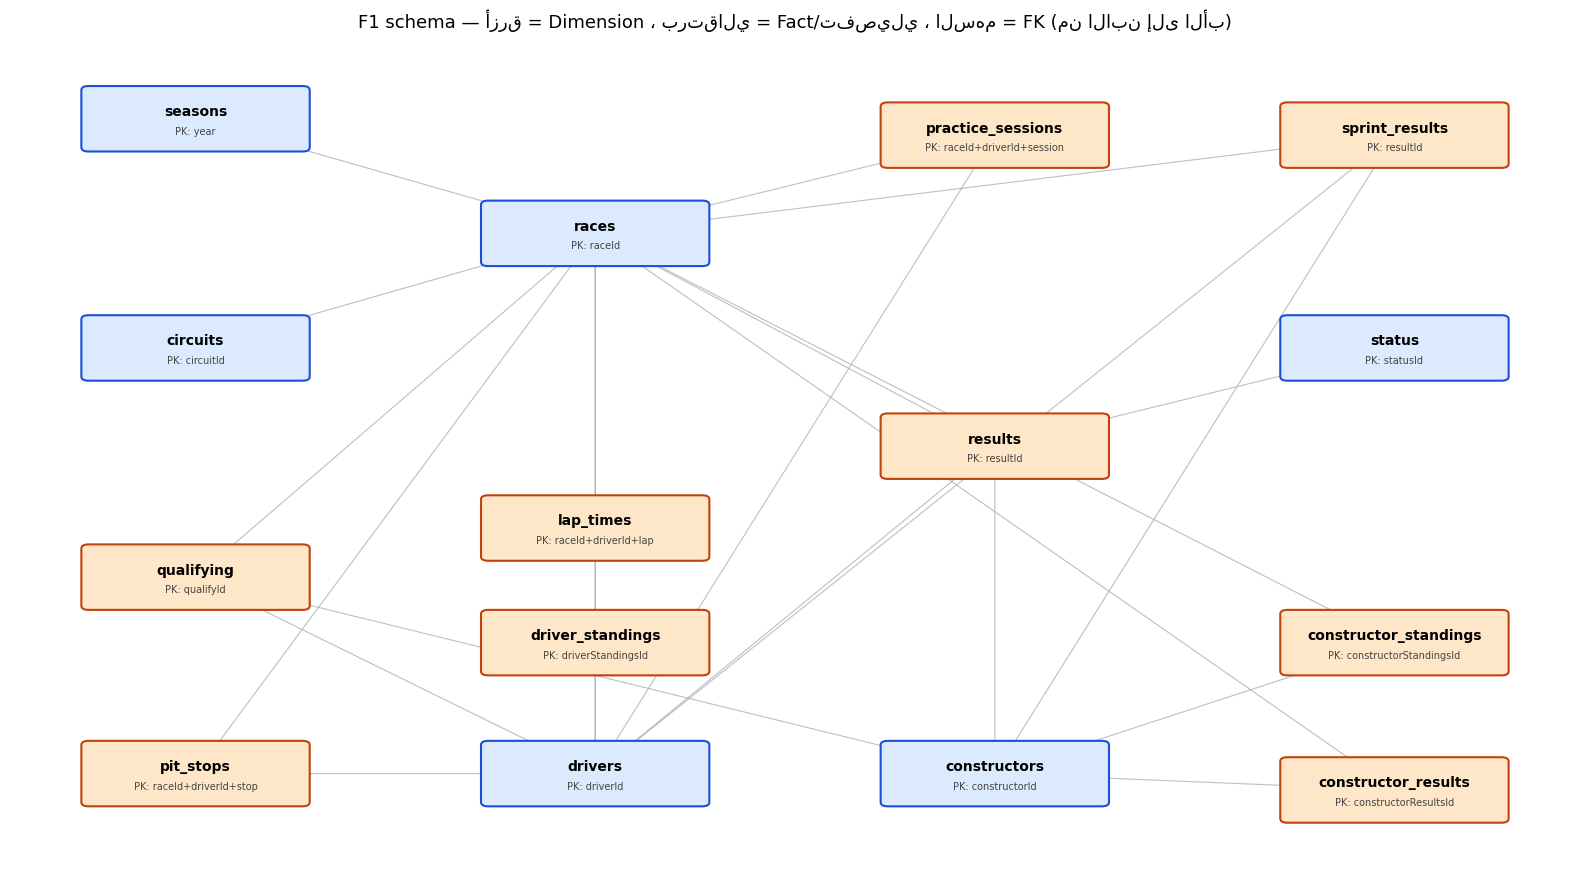

In [31]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# (x, y): مواضع الجداول — الأبعاد بالأطراف والحقائق بالمنتصف
POS = {
 "seasons": (0.08, 0.90), "circuits": (0.08, 0.62), "races": (0.36, 0.76),
 "drivers": (0.36, 0.10), "constructors": (0.64, 0.10), "status": (0.92, 0.62),
 "results": (0.64, 0.50), "sprint_results": (0.92, 0.88),
 "qualifying": (0.08, 0.34), "lap_times": (0.36, 0.40), "pit_stops": (0.08, 0.10),
 "driver_standings": (0.36, 0.26) , "constructor_standings": (0.92, 0.26),
 "constructor_results": (0.92, 0.08), "practice_sessions": (0.64, 0.88),
}
KIND = {t: "dim" for t in ["seasons","circuits","races","drivers","constructors","status"]}
PKTXT = {"seasons":"year","circuits":"circuitId","races":"raceId","drivers":"driverId","constructors":"constructorId",
         "status":"statusId","results":"resultId","sprint_results":"resultId","qualifying":"qualifyId",
         "lap_times":"raceId+driverId+lap","pit_stops":"raceId+driverId+stop","driver_standings":"driverStandingsId",
         "constructor_standings":"constructorStandingsId","constructor_results":"constructorResultsId",
         "practice_sessions":"raceId+driverId+session"}
FK_EDGES = [("races","seasons"),("races","circuits"),("results","races"),("results","drivers"),("results","constructors"),
  ("results","status"),("sprint_results","races"),("sprint_results","drivers"),("sprint_results","constructors"),
  ("qualifying","races"),("qualifying","drivers"),("qualifying","constructors"),("lap_times","races"),("lap_times","drivers"),
  ("pit_stops","races"),("pit_stops","drivers"),("driver_standings","races"),("driver_standings","drivers"),
  ("constructor_standings","races"),("constructor_standings","constructors"),("constructor_results","races"),
  ("constructor_results","constructors"),("practice_sessions","races"),("practice_sessions","drivers")]

fig, ax = plt.subplots(figsize=(16, 9)); ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.03, 1.0); ax.axis("off")
for a, b in FK_EDGES:
    (x1, y1), (x2, y2) = POS[a], POS[b]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#9aa5b1", lw=0.8, alpha=0.7), zorder=1)
for t, (x, y) in POS.items():
    dim = KIND.get(t) == "dim"
    ax.add_patch(FancyBboxPatch((x-0.075, y-0.035), 0.15, 0.07, boxstyle="round,pad=0.005",
                 fc="#dbeafe" if dim else "#fde7c8", ec="#1d4ed8" if dim else "#c2410c", lw=1.5, zorder=2))
    ax.text(x, y+0.008, t, ha="center", va="center", fontsize=10, fontweight="bold", zorder=3)
    ax.text(x, y-0.016, f"PK: {PKTXT[t]}", ha="center", va="center", fontsize=7, color="#444", zorder=3)
ax.set_title("F1 schema — أزرق = Dimension ، برتقالي = Fact/تفصيلي ، السهم = FK (من الابن إلى الأب)", fontsize=13)
plt.tight_layout(); plt.show()

## 3.3 `fact_results` — الجدول المحوري
أعمدة مشتقة (كلها بدون تضخيم عدد الصفوف — نفس عدد صفوف `results`):

- `is_win / is_podium / is_points_finish / has_fastest_lap / started_on_pole`
- `is_finish / is_dnf / is_dsq / is_dns` من `status_group` (عبر `status`)
- `positions_gained = grid − positionOrder` (**موجب = كسب مراكز**) للمُصنَّفين فقط ولمن انطلق من الشبكة العادية
- `laps_completed_pct = laps ÷ أكبر عدد لفات في السباق` (نسبة إكمال السباق)
- `quali_position / best_q_ms / reached_q3` من `qualifying` (join فريد على `raceId, driverId`)
- `age_at_race` (بالسنوات) من `drivers.dob`

In [32]:
races = T["races"]
ERA_BINS   = [1949, 1969, 1989, 2013, 2021, 2100]
ERA_LABELS = ["1950-69 Pioneer", "1970-89 Classic", "1990-2013 V10/V8", "2014-21 Hybrid", "2022+ Ground effect"]
races = races.assign(era=pd.cut(races["year"], ERA_BINS, labels=ERA_LABELS).astype("string"))   # عدّل الحدود لو تحب

res = T["results"].copy()
n0 = len(res)

# --- ربط السنة/الجولة/التاريخ ---
res = res.merge(races[["raceId", "year", "round", "date"]], on="raceId", how="left")

# --- ربط حالة الإنهاء ---
res = res.merge(T["status"][["statusId", "status_group"]], on="statusId", how="left")
sg = res["status_group"]
res["is_finish"] = sg.isin(["Finished", "Finished (Lapped)"])
res["is_dsq"]    = sg.eq("Disqualified")
res["is_dns"]    = sg.eq("DNS / Not classified")
res["is_dnf"]    = ~(res["is_finish"] | res["is_dsq"] | res["is_dns"])     # انسحاب فعلي (عطل/حادث/...)

# --- فوز / منصة / نقاط ---
pos = res["position"]
res["is_win"]           = pos.eq(1).fillna(False).astype(bool)
res["is_podium"]        = (pos <= 3).fillna(False).astype(bool)
res["is_points_finish"] = res["points"] > 0
res["has_fastest_lap"]  = res["rank"].eq(1).fillna(False).astype(bool)
res["started_on_pole"]  = res["grid_clean"].eq(1).fillna(False).astype(bool)

# --- مكاسب المراكز: فقط للمُصنَّفين الذين لهم grid حقيقي ---
ok = res["is_classified"] & res["grid_clean"].notna()
res["positions_gained"] = (res["grid_clean"].astype("float64") - res["positionOrder"]).where(ok).astype("Int16")

# --- نسبة إكمال السباق ---
res["race_laps"] = res.groupby("raceId")["laps"].transform("max").astype("int16")
res["laps_completed_pct"] = (res["laps"] / res["race_laps"]).round(4).astype("float32")

# --- التأهل (join فريد على raceId+driverId) ---
q = T["qualifying"][["raceId", "driverId", "position", "best_q_ms", "reached_q3"]].rename(columns={"position": "quali_position"})
assert not q.duplicated(["raceId", "driverId"]).any()
res = res.merge(q, on=["raceId", "driverId"], how="left")
res["reached_q3"] = res["reached_q3"].fillna(False).astype(bool)
res["has_quali_data"] = res["quali_position"].notna()

# --- العمر وقت السباق ---
res = res.merge(T["drivers"][["driverId", "dob"]], on="driverId", how="left")
res["age_at_race"] = ((res["date"] - res["dob"]).dt.days / 365.25).round(1).astype("float32")

fact_results = res[[
    "resultId", "raceId", "driverId", "constructorId", "statusId", "year", "round",
    "grid", "grid_clean", "grid_is_pitlane", "quali_position", "has_quali_data", "best_q_ms", "reached_q3",
    "position", "positionOrder", "points", "laps", "race_laps", "laps_completed_pct", "milliseconds",
    "fastest_lap_ms", "rank", "fastestLapSpeed",
    "is_classified", "is_finish", "is_dnf", "is_dsq", "is_dns", "is_win", "is_podium", "is_points_finish",
    "has_fastest_lap", "started_on_pole", "is_shared_drive", "positions_gained", "age_at_race",
]].copy()
fact_results["status_group"] = res["status_group"].astype("category")

assert len(fact_results) == n0, "الـ joins غيّرت عدد الصفوف!"
assert fact_results["resultId"].is_unique
print(f"fact_results: {fact_results.shape}  (نفس عدد صفوف results ✅)")
display(fact_results.sample(5, random_state=1)[["year","driverId","grid_clean","positionOrder","positions_gained","status_group","is_win","is_podium","laps_completed_pct"]])

fact_results: (26313, 38)  (نفس عدد صفوف results ✅)


,year,driverId,grid_clean,positionOrder,positions_gained,status_group,is_win,is_podium,laps_completed_pct
3854,1969,297,11,5,6,Finished (Lapped),False,False,0.988
18219,2007,768,7,10,-3,Finished,False,False,1.000
13120,1994,718,24,8,16,Finished (Lapped),False,False,0.952
2617,1963,297,5,2,3,Finished,False,True,1.000
19588,2011,770,5,5,0,Finished,False,False,1.000


## 3.4 `fact_driver_race_perf` — إحصاءات اللفات والـ Pit Stops
**Grain = (raceId, driverId)**. نستبعد `is_outlier_lap` و`is_outlier_stop` من المتوسطات (لكن نسجّل عددها).

In [33]:
lt = T["lap_times"]
clean_laps = lt[~lt["is_outlier_lap"]]
lap_stats = clean_laps.groupby(["raceId", "driverId"], observed=True)["milliseconds"].agg(
    best_lap_ms="min", avg_lap_ms="mean", median_lap_ms="median", lap_std_ms="std", n_clean_laps="count").reset_index()
lap_stats[["avg_lap_ms", "median_lap_ms", "lap_std_ms"]] = lap_stats[["avg_lap_ms", "median_lap_ms", "lap_std_ms"]].round(0)
lap_n = lt.groupby(["raceId", "driverId"], observed=True).agg(n_laps_recorded=("lap", "count"), n_outlier_laps=("is_outlier_lap", "sum")).reset_index()
lap1 = lt.loc[lt["lap"] == 1, ["raceId", "driverId", "position"]].rename(columns={"position": "lap1_position"})
lap_stats = lap_n.merge(lap_stats, on=["raceId", "driverId"], how="left").merge(lap1, on=["raceId", "driverId"], how="left")

ps = T["pit_stops"]
valid = ps[~ps["is_outlier_stop"]]
pit_stats = valid.groupby(["raceId", "driverId"], observed=True).agg(
    n_pit_stops=("stop", "count"), total_pit_s=("duration_s", "sum"), avg_pit_s=("duration_s", "mean"),
    first_stop_lap=("lap", "min")).reset_index()
pit_out = ps.groupby(["raceId", "driverId"], observed=True)["is_outlier_stop"].sum().rename("n_outlier_stops").reset_index()
pit_stats = pit_out.merge(pit_stats, on=["raceId", "driverId"], how="left")
pit_stats["n_pit_stops"] = pit_stats["n_pit_stops"].fillna(0).astype("int8")      # سائق لديه توقفات كلها شاذة = 0 صالحة

fact_perf = lap_stats.merge(pit_stats, on=["raceId", "driverId"], how="outer")
fact_perf["has_lap_data"] = fact_perf["n_laps_recorded"].notna()
fact_perf["has_pit_data"] = fact_perf["n_outlier_stops"].notna()
for c in ["n_laps_recorded", "n_outlier_laps", "n_outlier_stops"]:
    fact_perf[c] = fact_perf[c].fillna(0).astype("int16")
assert not fact_perf.duplicated(["raceId", "driverId"]).any()
print("fact_driver_race_perf:", fact_perf.shape, "| lap data:", int(fact_perf.has_lap_data.sum()), "| pit data:", int(fact_perf.has_pit_data.sum()))
display(fact_perf.dropna(subset=["avg_pit_s"]).head(3))

fact_driver_race_perf: (11938, 17) | lap data: 11938 | pit data: 6439


,raceId,driverId,n_laps_recorded,n_outlier_laps,best_lap_ms,avg_lap_ms,median_lap_ms,lap_std_ms,n_clean_laps,lap1_position,n_outlier_stops,n_pit_stops,total_pit_s,avg_pit_s,first_stop_lap,has_lap_data,has_pit_data
5234,840,703,19,0,"95,319.000","101,762.000","96,991.000","15,297.000",19.000,22,0,2.000,49.009,24.505,1.000,True,True
5235,840,715,48,0,"91,404.000","96,734.000","93,662.000","9,132.000",48.000,20,0,4.000,104.700,26.175,13.000,True,True
5236,840,747,56,0,"92,550.000","97,385.000","96,691.000","5,483.000",56.000,17,0,2.000,49.747,24.873,16.000,True,True


## 3.5 `fact_race_summary` — ملخص كل سباق
نسبة الإكمال، الفائز، صاحب الـ Pole، وهل فاز. ملاحظة: الفائز يُحدَّد بـ `positionOrder == 1` (لأن 3 سباقات في الخمسينات انتهت بفوز مشترك لسائقَين ويظهر لهما `position = 1`).

In [34]:
fr = fact_results
starters = fr[~fr["is_dns"]]
g = starters.groupby("raceId")
summ = pd.DataFrame({
    "starters": g.size(),
    "finishers": g["is_finish"].sum(),
    "dnf_count": g["is_dnf"].sum(),
    "dsq_count": fr.groupby("raceId")["is_dsq"].sum(),
    "race_laps": fr.groupby("raceId")["race_laps"].first(),
    "best_fastest_lap_ms": fr.groupby("raceId")["fastest_lap_ms"].min(),
}).reset_index()
summ["finish_rate"] = (summ["finishers"] / summ["starters"]).round(4)
summ["dnf_rate"]    = (summ["dnf_count"] / summ["starters"]).round(4)

winner = fr[fr["positionOrder"] == 1].drop_duplicates("raceId")[["raceId", "driverId", "constructorId", "grid_clean"]]
winner.columns = ["raceId", "winner_driverId", "winner_constructorId", "winner_grid"]
pole = fr[fr["grid_clean"] == 1].drop_duplicates("raceId")[["raceId", "driverId"]].rename(columns={"driverId": "pole_driverId"})
summ = summ.merge(winner, on="raceId", how="left").merge(pole, on="raceId", how="left")
summ["pole_won"] = (summ["winner_driverId"] == summ["pole_driverId"]).where(summ["pole_driverId"].notna())

# تعداد الـ Pit Stops (فقط للسباقات التي لها بيانات pit)
pit_race = fact_perf[fact_perf["has_pit_data"]].groupby("raceId").agg(
    drivers_with_pit_data=("driverId", "nunique"), total_pit_stops=("n_pit_stops", "sum")).reset_index()
pit_race["avg_stops_per_driver"] = (pit_race["total_pit_stops"] / pit_race["drivers_with_pit_data"]).round(2)
summ = summ.merge(pit_race[["raceId", "total_pit_stops", "avg_stops_per_driver"]], on="raceId", how="left")

# تحويل pole_won لـ boolean nullable
summ["pole_won"] = summ["pole_won"].astype("boolean")
summ = summ.merge(races[["raceId", "year", "round", "circuitId", "era"]], on="raceId", how="left")
fact_race_summary = summ
assert fact_race_summary["raceId"].is_unique and len(fact_race_summary) == races.shape[0]
print("fact_race_summary:", fact_race_summary.shape)
print("نسبة فوز صاحب الـ Pole (كل التاريخ): {:.1%}".format(fact_race_summary["pole_won"].dropna().astype(float).mean()))

fact_race_summary: (1169, 20)
نسبة فوز صاحب الـ Pole (كل التاريخ): 43.9%


## 3.6 تجميعات الموسم: `agg_driver_season` و `agg_constructor_season`
- النقاط والمركز النهائي من **آخر جولة في الموسم** في جداول الـ standings (تشمل نقاط الـ Sprint، بخلاف مجموع `results.points`).
- `champion = (final_position == 1)`.

In [35]:
last_race = races.loc[races.groupby("year")["round"].idxmax(), ["raceId", "year"]].rename(columns={"raceId": "last_raceId"})

def season_agg(fr, key):
    g = fr.groupby([key, "year"])
    out = g.agg(
        starts=("resultId", "count"), wins=("is_win", "sum"), podiums=("is_podium", "sum"),
        poles=("started_on_pole", "sum"), fastest_laps=("has_fastest_lap", "sum"),
        dnfs=("is_dnf", "sum"), points_from_races=("points", "sum"),
        finish_count=("is_finish", "sum"), avg_grid=("grid_clean", lambda s: s.astype("float64").mean()),
        avg_finish=("positionOrder", "mean")).reset_index()
    out["finish_rate"] = (out["finish_count"] / out["starts"]).round(4)
    out["win_rate"] = (out["wins"] / out["starts"]).round(4)
    out["podium_rate"] = (out["podiums"] / out["starts"]).round(4)
    return out.drop(columns="finish_count")

# ---- السائقون ----
ads = season_agg(fact_results, "driverId")
fin = T["driver_standings"].merge(last_race, left_on="raceId", right_on="last_raceId")[["driverId", "year", "points", "position", "wins"]]
fin = fin.rename(columns={"points": "final_points", "position": "final_position", "wins": "standings_wins"})
agg_driver_season = ads.merge(fin, on=["driverId", "year"], how="left")
agg_driver_season["champion"] = agg_driver_season["final_position"].eq(1).fillna(False).astype(bool)

# ---- الفرق ----
acs = season_agg(fact_results, "constructorId")
finc = T["constructor_standings"].merge(last_race, left_on="raceId", right_on="last_raceId")[["constructorId", "year", "points", "position", "wins"]]
finc = finc.rename(columns={"points": "final_points", "position": "final_position", "wins": "standings_wins"})
agg_constructor_season = acs.merge(finc, on=["constructorId", "year"], how="left")
agg_constructor_season["champion"] = agg_constructor_season["final_position"].eq(1).fillna(False).astype(bool)

# ---- فحوصات منطقية ----
assert agg_driver_season.duplicated(["driverId", "year"]).sum() == 0
champs = agg_driver_season[agg_driver_season.champion].groupby("year").size()
print("سنوات لها بطل واحد بالضبط:", int((champs == 1).sum()), "من", races.year.nunique(), "| سنوات بلا بطل/بأكثر من بطل:", sorted(set(races.year.unique()) - set(champs[champs == 1].index)))
print("أبطال آخر 5 مواسم:")
names = T["drivers"].set_index("driverId")["driver_name"]
display(agg_driver_season[agg_driver_season.champion].sort_values("year").tail(5).assign(driver=lambda d: d.driverId.map(names))[["year", "driver", "wins", "final_points"]])

# مقارنة نقاط السباقات بنقاط الـ standings (الفروق متوقعة: Sprint 2021+ ونظام أفضل-N نتائج قديماً)
diff = agg_driver_season.dropna(subset=["final_points"]).assign(d=lambda d: (d.final_points - d.points_from_races).abs() > 0.01)
print("نسبة صفوف السائق-موسم التي تختلف فيها نقاط الـ standings عن مجموع results:", f"{diff.d.mean():.1%}", "(أغلبها سنوات الـ Sprint ونظام الـ best-N)")

سنوات لها بطل واحد بالضبط: 77 من 77 | سنوات بلا بطل/بأكثر من بطل: []
أبطال آخر 5 مواسم:


,year,driver,wins,final_points
3001,2022,Max Verstappen,15,454.000
3002,2023,Max Verstappen,19,575.000
3003,2024,Max Verstappen,9,437.000
3068,2025,Lando Norris,7,423.000
3125,2026,Andrea Kimi Antonelli,9,390.000


نسبة صفوف السائق-موسم التي تختلف فيها نقاط الـ standings عن مجموع results: 4.0% (أغلبها سنوات الـ Sprint ونظام الـ best-N)


## 3.7 `agg_circuit` — الحلبات: الانسحاب والإثارة واستراتيجية الـ Pit

In [36]:
fr = fact_results
cls = fr[fr["positions_gained"].notna()].merge(races[["raceId", "circuitId"]], on="raceId")
overtake = cls.groupby("circuitId").agg(avg_abs_positions_change=("positions_gained", lambda s: s.astype("float64").abs().mean())).reset_index()

rs = fact_race_summary
circ = rs.groupby("circuitId").agg(
    n_races=("raceId", "count"), first_year=("year", "min"), last_year=("year", "max"),
    total_starters=("starters", "sum"), total_dnf=("dnf_count", "sum"),
    avg_finish_rate=("finish_rate", "mean"), pole_win_rate=("pole_won", lambda s: s.dropna().astype(float).mean()),
    avg_stops_per_driver=("avg_stops_per_driver", "mean"), n_races_with_pit_data=("avg_stops_per_driver", "count"),
).reset_index()
circ["dnf_rate"] = (circ["total_dnf"] / circ["total_starters"]).round(4)
agg_circuit = (circ.merge(overtake, on="circuitId", how="left")
                   .merge(T["circuits"][["circuitId", "name", "country_std"]].rename(columns={"name": "circuit_name"}), on="circuitId", how="left"))
print("agg_circuit:", agg_circuit.shape)
display(agg_circuit[agg_circuit.n_races >= 20].sort_values("dnf_rate", ascending=False).head(8)[
    ["circuit_name", "country_std", "n_races", "dnf_rate", "pole_win_rate", "avg_abs_positions_change", "avg_stops_per_driver"]])

agg_circuit: (78, 14)


,circuit_name,country_std,n_races,dnf_rate,pole_win_rate,avg_abs_positions_change,avg_stops_per_driver
26,Kyalami,South Africa,20,0.485,0.200,6.103,NaN
20,Watkins Glen,United States,20,0.478,0.500,5.620,NaN
11,Autódromo Juan y Oscar Gálvez,Argentina,20,0.473,0.400,4.707,NaN
1,Circuit de Monaco,Monaco,72,0.463,0.472,4.349,1.630
44,Autodromo Enzo e Dino Ferrari,Italy,32,0.462,0.344,4.507,1.644
32,Hockenheimring,Germany,37,0.437,0.486,4.733,2.814
7,Nürburgring,Germany,41,0.432,0.366,4.811,2.210
10,Circuit Park Zandvoort,Netherlands,36,0.413,0.500,4.323,2.497


## 3.8 فحوصات سلامة نهائية + حفظ المخرجات

In [37]:
# --- sanity: أكثر الفائزين (يجب أن تبدو منطقية) ---
dn = T["drivers"].set_index("driverId")["driver_name"]; cn = T["constructors"].set_index("constructorId")["constructor_name"]
top_d = fact_results.groupby("driverId")[["is_win", "is_podium"]].sum().sort_values("is_win", ascending=False).head(5)
top_c = fact_results.groupby("constructorId")[["is_win", "is_podium"]].sum().sort_values("is_win", ascending=False).head(5)
display(top_d.rename(index=dn)); display(top_c.rename(index=cn))

# --- اتساق: مجموع الانتصارات ---
assert agg_driver_season["wins"].sum() == fact_results["is_win"].sum()
assert fact_race_summary["winner_driverId"].notna().all()
assert fact_results["laps_completed_pct"].between(0, 1.0001).all()
assert fact_results["positions_gained"].dropna().abs().max() < 40

# --- حفظ ---
OUT = dict(fact_results=fact_results, fact_driver_race_perf=fact_perf, fact_race_summary=fact_race_summary,
           agg_driver_season=agg_driver_season, agg_constructor_season=agg_constructor_season, agg_circuit=agg_circuit)
rows = []
for n, df in OUT.items():
    df = df.reset_index(drop=True)
    try: p = MODEL_DIR / f"{n}.parquet"; df.to_parquet(p, index=False)
    except ImportError: p = MODEL_DIR / f"{n}.csv"; df.to_csv(p, index=False)
    rows.append(dict(table=n, rows=len(df), cols=df.shape[1], size_MB=round(p.stat().st_size / 1024**2, 2)))
display(pd.DataFrame(rows).set_index("table"))
print("✅ المخرجات في:", MODEL_DIR)

,is_win,is_podium
driverId,,
Lewis Hamilton,106,209
Michael Schumacher,91,155
Max Verstappen,74,139
Sebastian Vettel,53,122
Alain Prost,51,106


,is_win,is_podium
constructorId,,
Ferrari,251,861
McLaren,202,550
Mercedes,143,334
Red Bull,133,312
Williams,114,316


,rows,cols,size_MB
table,,,
fact_results,26313,38,0.640
fact_driver_race_perf,11938,17,0.390
fact_race_summary,1169,20,0.040
agg_driver_season,3131,18,0.060
agg_constructor_season,1110,18,0.040
agg_circuit,78,14,0.010


✅ المخرجات في: /content/f1_model


# 🏎️ تحليل بيانات Formula 1 — المرحلة 4
**الاستكشاف واستخراج الـ Insights (EDA & Key Insights)**

المدخل: `/content/f1_clean` (المرحلة 2) و`/content/f1_model` (المرحلة 3).  
المخرج: 8 تحليلات برسوم احترافية (عناوين الرسوم بالإنجليزية لتناسب الـ Portfolio) محفوظة في `/content/f1_figures`.

| # | السؤال |
|---|---|
| 1 | من أكثر السائقين تحقيقاً للفوز والمنصات ونسب الفوز؟ |
| 2 | أي الفرق سيطرت في أي عقد؟ |
| 3 | كيف يؤثر مركز الانطلاق على الفوز والمنصة؟ |
| 4 | أي الحلبات أكثر انسحاباً، وأيها يحوّل الـ Pole إلى فوز؟ |
| 5 | كيف تطورت الموثوقية والمنافسة عبر المواسم؟ |
| 6 | كيف تختلف سباقات السرعة (Sprint) عن السباق الرئيسي؟ |
| 7 | هل تتنبأ جلسات التجارب الحرة بمركز الانطلاق؟ (بيانات 2025+ فقط) |
| 8 | كيف تغيرت استراتيجية الـ Pit Stops منذ 2011؟ |

## 4.1 التحميل والإعداد

In [38]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.3f}".format)
try:
    from IPython.display import display
except ImportError:
    display = print
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE      = Path("/content") if IN_COLAB else Path(os.environ.get("F1_WORKDIR", "/tmp/f1"))
CLEAN_DIR, MODEL_DIR = BASE / "f1_clean", BASE / "f1_model"
FIG_DIR = BASE / "f1_figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

def read(folder, name):
    p = folder / f"{name}.parquet"
    return pd.read_parquet(p) if p.exists() else pd.read_csv(folder / f"{name}.csv")

fr   = read(MODEL_DIR, "fact_results")
perf = read(MODEL_DIR, "fact_driver_race_perf")
rs   = read(MODEL_DIR, "fact_race_summary")
C = {n: read(CLEAN_DIR, n) for n in ["drivers", "constructors", "circuits", "races", "sprint_results", "pit_stops", "practice_sessions"]}

driver_name = C["drivers"].set_index("driverId")["driver_name"]
team_name   = C["constructors"].set_index("constructorId")["constructor_name"]
circuit_name = C["circuits"].set_index("circuitId")["name"]
race_year   = C["races"].set_index("raceId")["year"]

ERA_BINS   = [1949, 1969, 1989, 2013, 2021, 2100]
ERA_LABELS = ["1950-69 Pioneer", "1970-89 Classic", "1990-2013 V10/V8", "2014-21 Hybrid", "2022+ Ground effect"]
fr["era"] = pd.cut(fr["year"], ERA_BINS, labels=ERA_LABELS)
fr["decade"] = fr["year"] // 10 * 10
starters = fr[~fr["is_dns"]]

ACCENT, INK, GREY, GRID = "#E10600", "#15151E", "#8A8D93", "#E5E7EB"
ERA_COLORS = ["#9CA3AF", "#6B7280", "#3B82F6", ACCENT, INK]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left"})

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG_DIR / name, dpi=150, facecolor="white"); plt.show()

def barh(ax, labels, values, title, xlabel, fmt="{:,.0f}", color=ACCENT):
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, color=color, height=0.65); ax.set_yticks(y, labels); ax.grid(axis="y", visible=False)
    for yi, v in zip(y, values): ax.text(v, yi, " " + fmt.format(v), va="center", fontsize=9)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_xlim(0, max(values) * 1.15)

print(f"{len(fr):,} results | {fr.year.min()}-{fr.year.max()} | {fr.raceId.nunique():,} races")

26,313 results | 1950-2026 | 1,169 races


## 1️⃣ أفضل السائقين: الفوز والمنصات ونسبة الفوز

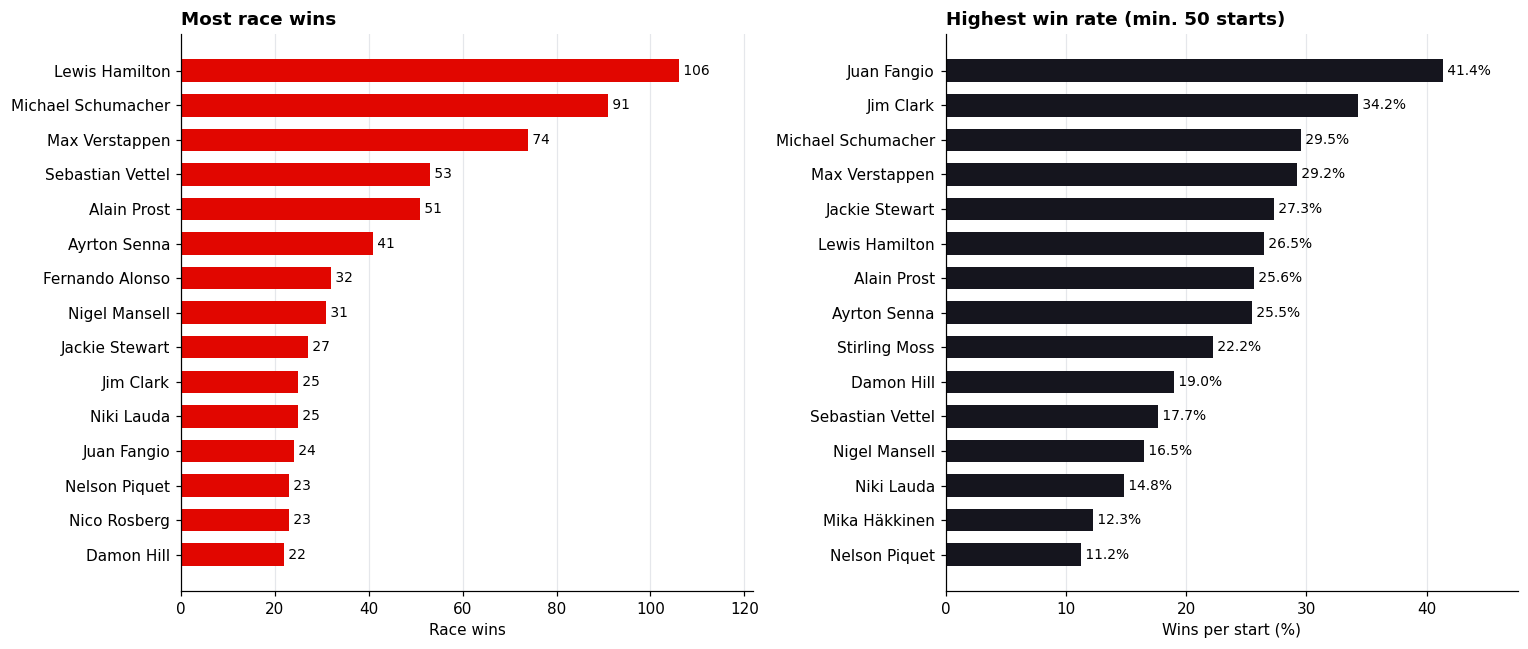

,name,starts,wins,podiums,poles,win_rate
0,Lewis Hamilton,400,106,209,105,0.265
1,Michael Schumacher,308,91,155,68,0.295
2,Max Verstappen,253,74,139,50,0.292
3,Sebastian Vettel,300,53,122,57,0.177
4,Alain Prost,199,51,106,32,0.256
5,Ayrton Senna,161,41,80,65,0.255
6,Fernando Alonso,446,32,106,22,0.072
7,Nigel Mansell,188,31,59,32,0.165
8,Jackie Stewart,99,27,43,17,0.273
9,Jim Clark,73,25,32,34,0.342


In [39]:
d = starters.groupby("driverId").agg(starts=("resultId", "count"), wins=("is_win", "sum"), podiums=("is_podium", "sum"),
                                     poles=("started_on_pole", "sum"), points=("points", "sum"))
d["win_rate"], d["podium_rate"] = d.wins / d.starts, d.podiums / d.starts
d["name"] = d.index.map(driver_name)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top = d.nlargest(15, "wins")
barh(axes[0], top["name"], top["wins"], "Most race wins", "Race wins")
top_rate = d[d.starts >= 50].nlargest(15, "win_rate")
barh(axes[1], top_rate["name"], top_rate["win_rate"] * 100, "Highest win rate (min. 50 starts)", "Wins per start (%)", "{:.1f}%", INK)
save(fig, "01_driver_leaders.png")
display(top[["name", "starts", "wins", "podiums", "poles", "win_rate"]].reset_index(drop=True))

## 2️⃣ سيطرة الفرق عبر العقود

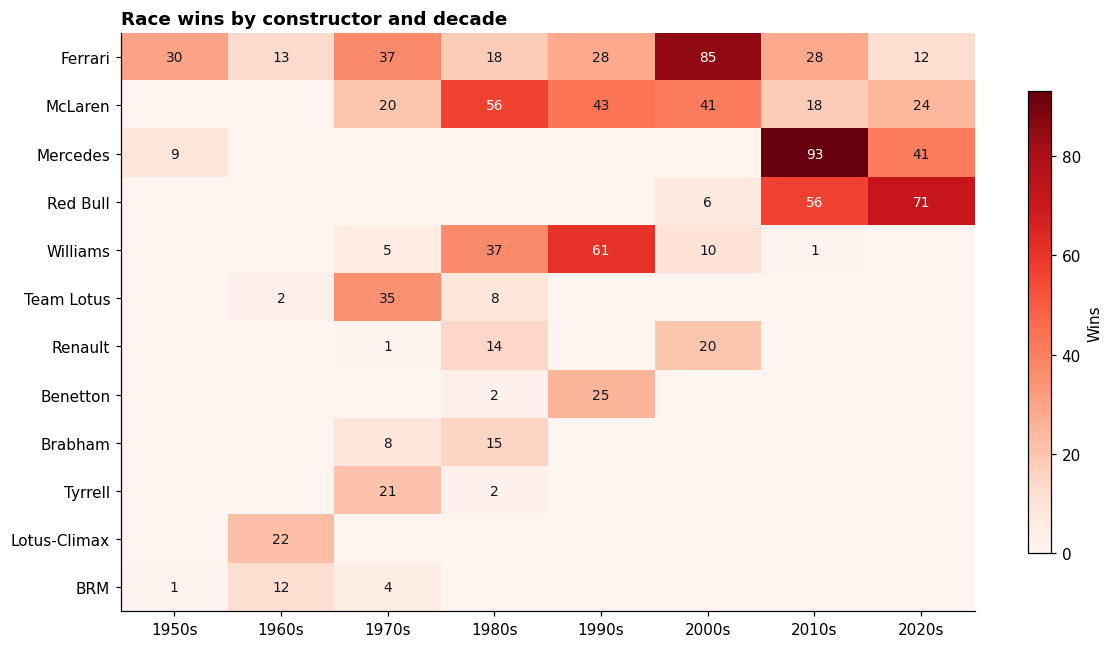

Share of all race wins:


,share_%
constructorId,
Ferrari,21.400
McLaren,17.200
Mercedes,12.200
Red Bull,11.300
Williams,9.700
Team Lotus,3.800


In [40]:
w = fr[fr.is_win].groupby(["constructorId", "decade"]).size().unstack(fill_value=0)
leaders = w.sum(axis=1).nlargest(12).index
heat = w.loc[leaders].rename(index=team_name)

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(heat.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(heat.shape[1]), [f"{c}s" for c in heat.columns]); ax.set_yticks(range(heat.shape[0]), heat.index); ax.grid(False)
for (r, c), v in np.ndenumerate(heat.values):
    if v: ax.text(c, r, int(v), ha="center", va="center", fontsize=9, color="white" if v > heat.values.max() * 0.55 else INK)
ax.set_title("Race wins by constructor and decade"); fig.colorbar(im, ax=ax, label="Wins", shrink=0.8)
save(fig, "02_constructor_decades.png")

share = (w.loc[leaders].sum(axis=1) / fr.is_win.sum()).rename(index=team_name).sort_values(ascending=False)
print("Share of all race wins:"); display((share * 100).round(1).head(6).to_frame("share_%"))

## 3️⃣ تأثير مركز الانطلاق

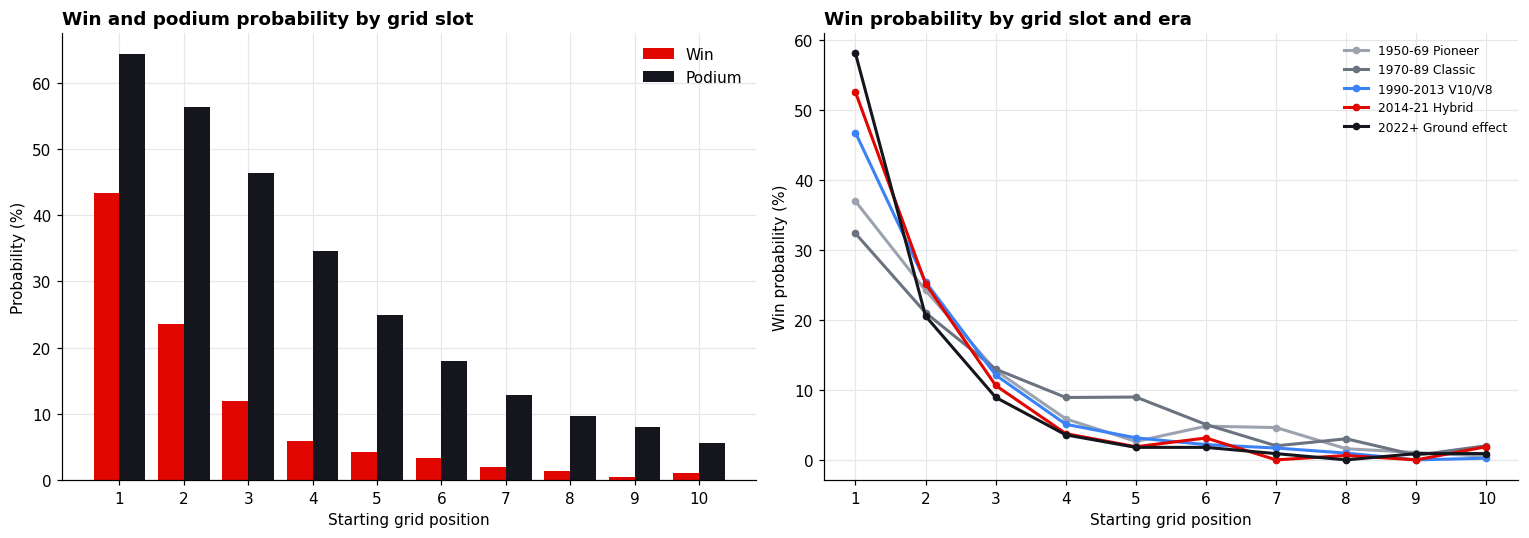

Pole win rate: 43.3% | Pole podium rate: 64.2%
Pole win rate by era:


,pole_win_%
era,
1950-69 Pioneer,36.900
1970-89 Classic,32.300
1990-2013 V10/V8,46.700
2014-21 Hybrid,52.500
2022+ Ground effect,58.000


In [41]:
front = fr[fr.grid_clean.between(1, 10)]
overall = front.groupby("grid_clean").agg(win=("is_win", "mean"), podium=("is_podium", "mean"))
by_era = front.groupby(["era", "grid_clean"], observed=True)["is_win"].mean().unstack("era")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = overall.index.to_numpy()
axes[0].bar(x - 0.2, overall["win"] * 100, 0.4, color=ACCENT, label="Win")
axes[0].bar(x + 0.2, overall["podium"] * 100, 0.4, color=INK, label="Podium")
axes[0].set_xticks(x); axes[0].set_xlabel("Starting grid position"); axes[0].set_ylabel("Probability (%)")
axes[0].set_title("Win and podium probability by grid slot"); axes[0].legend(frameon=False)
for color, era in zip(ERA_COLORS, by_era.columns):
    axes[1].plot(by_era.index, by_era[era] * 100, marker="o", ms=4, lw=2, color=color, label=era)
axes[1].set_xticks(x); axes[1].set_xlabel("Starting grid position"); axes[1].set_ylabel("Win probability (%)")
axes[1].set_title("Win probability by grid slot and era"); axes[1].legend(frameon=False, fontsize=8)
save(fig, "03_grid_effect.png")

print(f"Pole win rate: {overall.loc[1, 'win']:.1%} | Pole podium rate: {overall.loc[1, 'podium']:.1%}")
print("Pole win rate by era:"); display((by_era.loc[1] * 100).round(1).to_frame("pole_win_%"))

## 4️⃣ الحلبات: الانسحاب وتحويل الـ Pole إلى فوز (منذ 2000، 10 سباقات على الأقل)

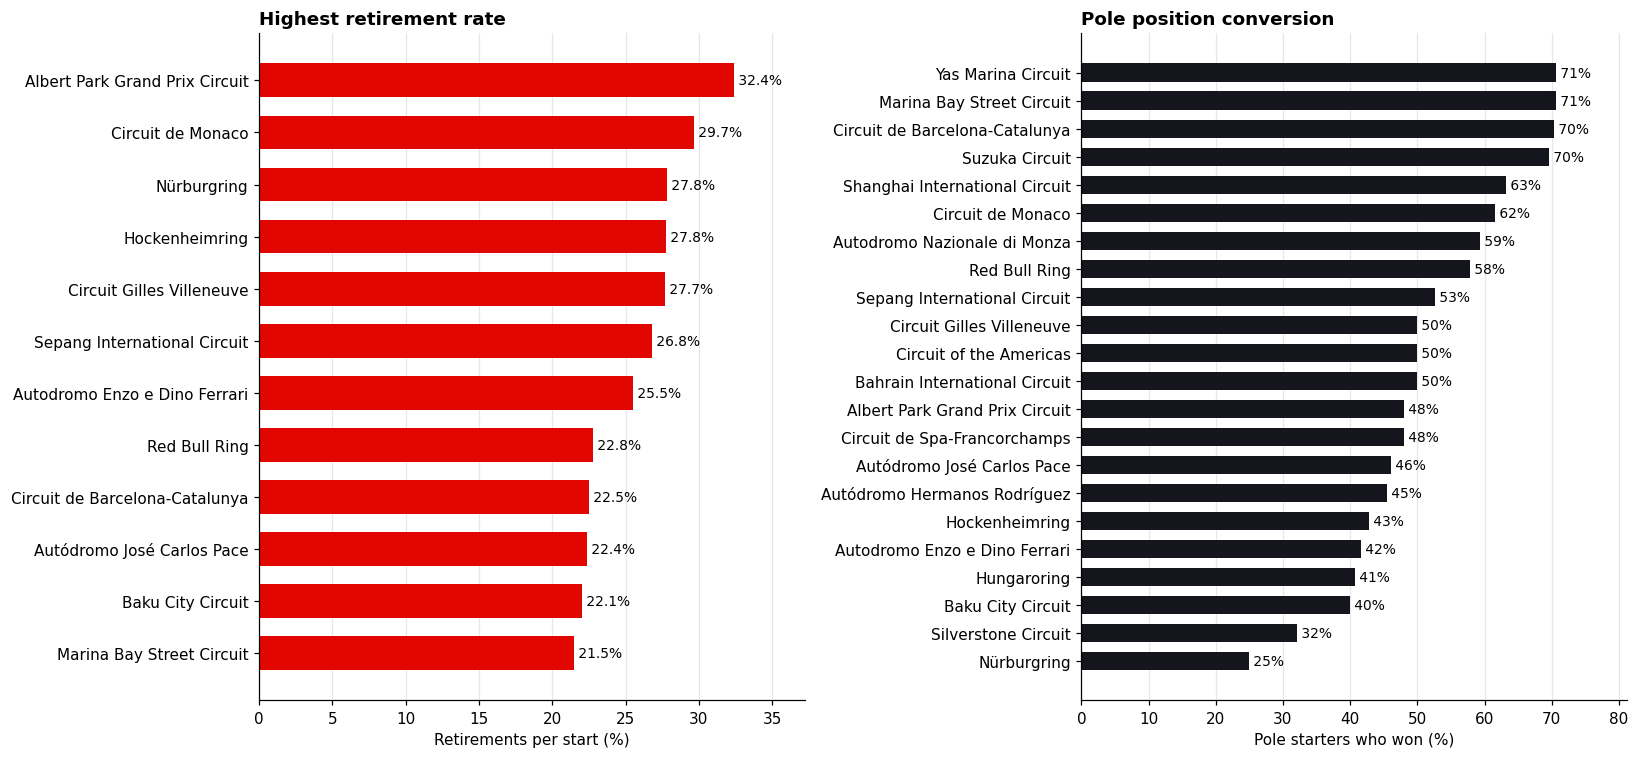

In [42]:
modern = rs[rs.year >= 2000]
c = modern.groupby("circuitId").agg(races=("raceId", "count"), starters=("starters", "sum"), dnf=("dnf_count", "sum"),
                                    pole_win_rate=("pole_won", lambda s: s.dropna().astype(float).mean()))
c["dnf_rate"] = c.dnf / c.starters
c = c[c.races >= 10]; c["circuit"] = c.index.map(circuit_name)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
t1 = c.nlargest(12, "dnf_rate")
barh(axes[0], t1["circuit"], t1["dnf_rate"] * 100, "Highest retirement rate", "Retirements per start (%)", "{:.1f}%")
t2 = c.sort_values("pole_win_rate", ascending=False)
barh(axes[1], t2["circuit"], t2["pole_win_rate"] * 100, "Pole position conversion", "Pole starters who won (%)", "{:.0f}%", INK)
save(fig, "04_circuits.png")

## 5️⃣ تطور الموثوقية والمنافسة عبر المواسم

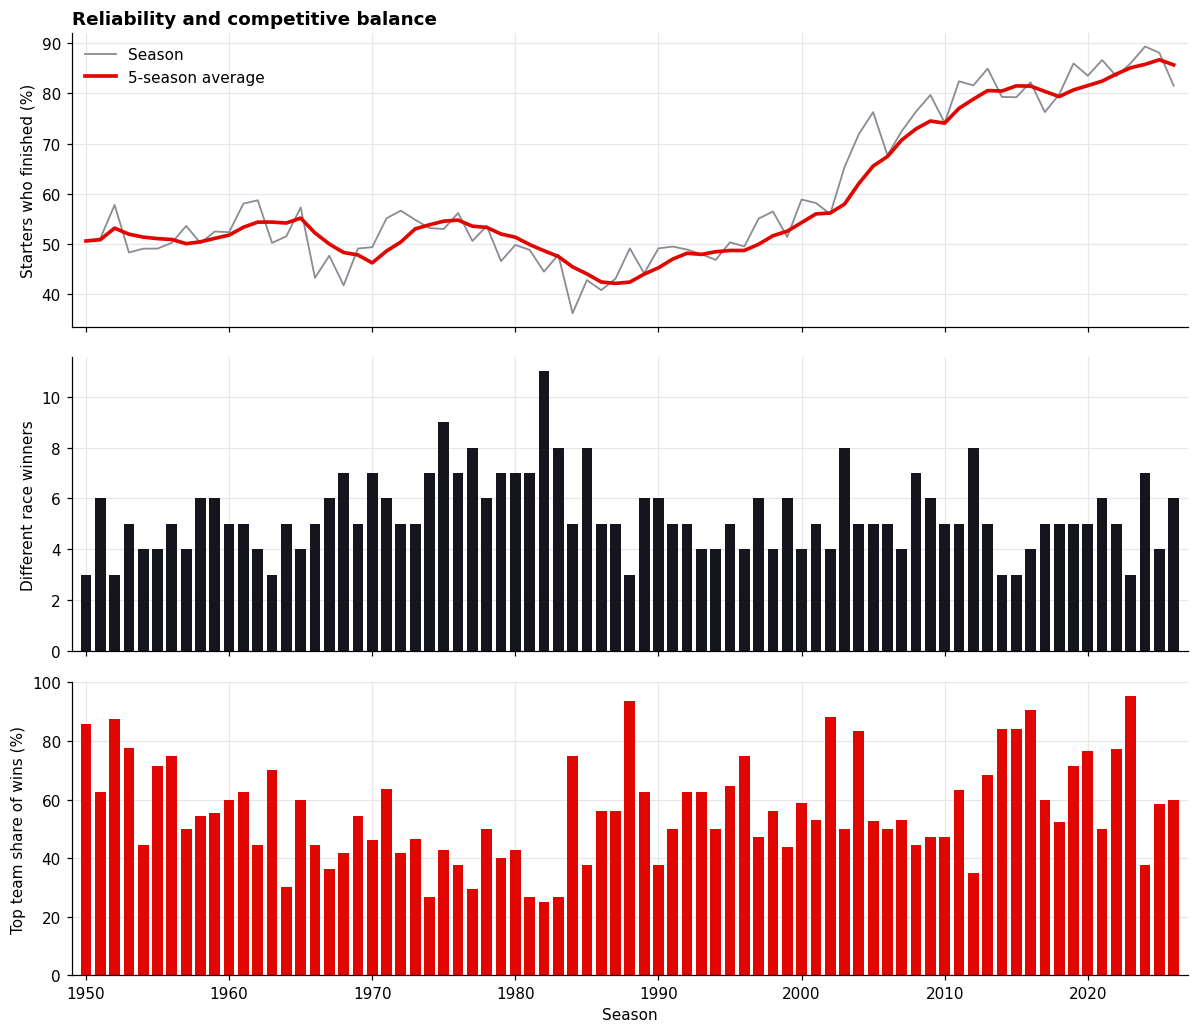

Most dominant seasons (top team share of wins):


,share_%
year,
2023,95.500
1988,93.800
2016,90.500
2002,88.200
1952,87.500


In [43]:
season = rs.groupby("year").agg(starters=("starters", "sum"), finishers=("finishers", "sum"))
season["finish_rate"] = season.finishers / season.starters
season["finish_rate_5y"] = season.finish_rate.rolling(5, min_periods=1).mean()
season["distinct_winners"] = fr[fr.is_win].groupby("year")["driverId"].nunique()
team_wins = fr[fr.is_win].groupby(["year", "constructorId"]).size()
races_per_year = rs.groupby("year").size()
season["top_team_win_share"] = team_wins.groupby("year").max() / races_per_year

fig, axes = plt.subplots(3, 1, figsize=(11, 9.5), sharex=True)
axes[0].plot(season.index, season.finish_rate * 100, color=GREY, lw=1.2, label="Season")
axes[0].plot(season.index, season.finish_rate_5y * 100, color=ACCENT, lw=2.4, label="5-season average")
axes[0].set_ylabel("Starters who finished (%)"); axes[0].set_title("Reliability and competitive balance"); axes[0].legend(frameon=False)
axes[1].bar(season.index, season.distinct_winners, color=INK, width=0.75); axes[1].set_ylabel("Different race winners")
axes[2].bar(season.index, season.top_team_win_share * 100, color=ACCENT, width=0.75); axes[2].set_ylabel("Top team share of wins (%)")
axes[2].set_xlabel("Season"); axes[2].set_xlim(season.index.min() - 1, season.index.max() + 1)
save(fig, "05_season_trends.png")

print("Most dominant seasons (top team share of wins):")
display((season.top_team_win_share.nlargest(5) * 100).round(1).to_frame("share_%"))

## 6️⃣ سباقات السرعة (Sprint) مقابل السباق الرئيسي

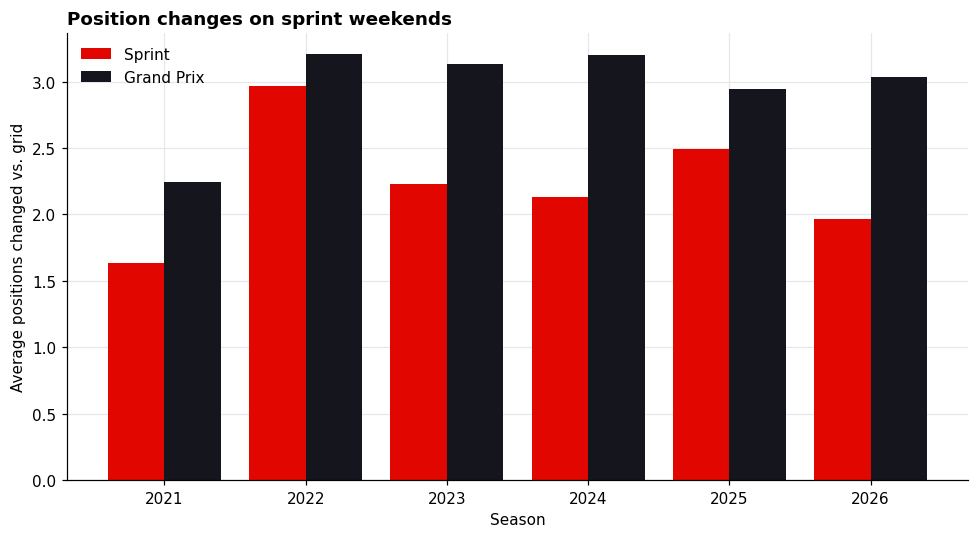

30 sprint weekends | the sprint winner also won the Grand Prix in 37% of them


In [44]:
S = C["sprint_results"].copy()
S["year"] = S.raceId.map(race_year)
S["gained"] = (S.grid.where(S.grid > 0) - S.positionOrder).where(S.position.notna())
gp = fr[fr.raceId.isin(S.raceId.unique())].dropna(subset=["positions_gained"])

cmp = pd.DataFrame({"Sprint": S.dropna(subset=["gained"]).groupby("year")["gained"].apply(lambda s: s.abs().mean()),
                    "Grand Prix": gp.groupby("year")["positions_gained"].apply(lambda s: s.astype("float64").abs().mean())})
sprint_winner = S[S.positionOrder == 1].set_index("raceId")["driverId"]
gp_winner = fr[fr.positionOrder == 1].drop_duplicates("raceId").set_index("raceId")["driverId"]
same = (sprint_winner == gp_winner.reindex(sprint_winner.index)).mean()

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(cmp)); ax.bar(x - 0.2, cmp["Sprint"], 0.4, color=ACCENT, label="Sprint"); ax.bar(x + 0.2, cmp["Grand Prix"], 0.4, color=INK, label="Grand Prix")
ax.set_xticks(x, cmp.index.astype(int)); ax.set_ylabel("Average positions changed vs. grid"); ax.set_xlabel("Season")
ax.set_title("Position changes on sprint weekends"); ax.legend(frameon=False)
save(fig, "06_sprint_effect.png")
print(f"{S.raceId.nunique()} sprint weekends | the sprint winner also won the Grand Prix in {same:.0%} of them")

## 7️⃣ جلسات التجارب الحرة وتنبؤها بالانطلاق (2025+ فقط)

41 race weekends with practice data (2025-2026)


,vs_grid,vs_finish
mean,0.720,0.690
min,0.220,0.010
max,0.970,0.960


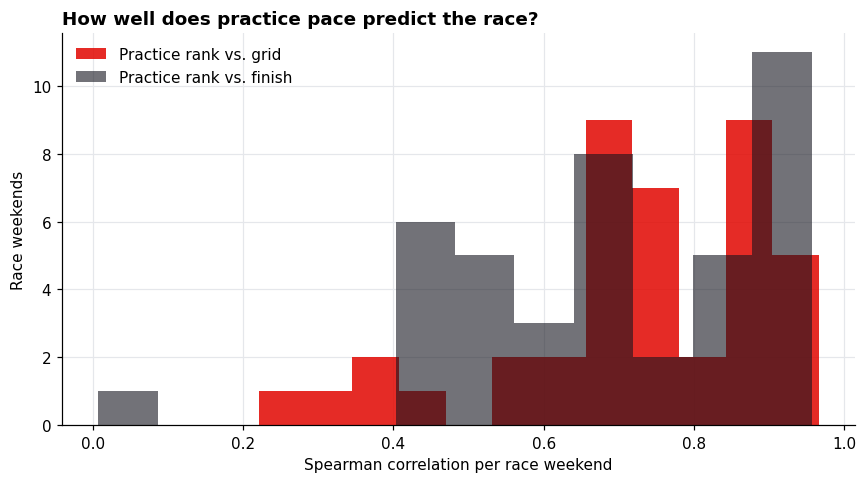

In [45]:
P = C["practice_sessions"].dropna(subset=["milliseconds"])
best = P.groupby(["raceId", "driverId"])["milliseconds"].min().reset_index()
best["practice_rank"] = best.groupby("raceId")["milliseconds"].rank(method="min")
m = best.merge(fr[["raceId", "driverId", "grid_clean", "positionOrder", "is_classified"]], on=["raceId", "driverId"])

def race_corr(g, target):
    g = g.dropna(subset=[target])
    return g["practice_rank"].corr(g[target].astype("float64"), method="spearman") if len(g) >= 10 else np.nan

corr = pd.DataFrame({"vs_grid": m.groupby("raceId").apply(race_corr, "grid_clean"),
                     "vs_finish": m[m.is_classified].groupby("raceId").apply(race_corr, "positionOrder")}).dropna(how="all")
print(f"{m.raceId.nunique()} race weekends with practice data ({int(race_year[m.raceId].min())}-{int(race_year[m.raceId].max())})")
display(corr.describe().loc[["mean", "min", "max"]].round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(corr["vs_grid"].dropna(), bins=12, color=ACCENT, alpha=0.85, label="Practice rank vs. grid")
ax.hist(corr["vs_finish"].dropna(), bins=12, color=INK, alpha=0.6, label="Practice rank vs. finish")
ax.set_xlabel("Spearman correlation per race weekend"); ax.set_ylabel("Race weekends")
ax.set_title("How well does practice pace predict the race?"); ax.legend(frameon=False)
save(fig, "07_practice_predictiveness.png")

## 8️⃣ استراتيجية الـ Pit Stops منذ 2011

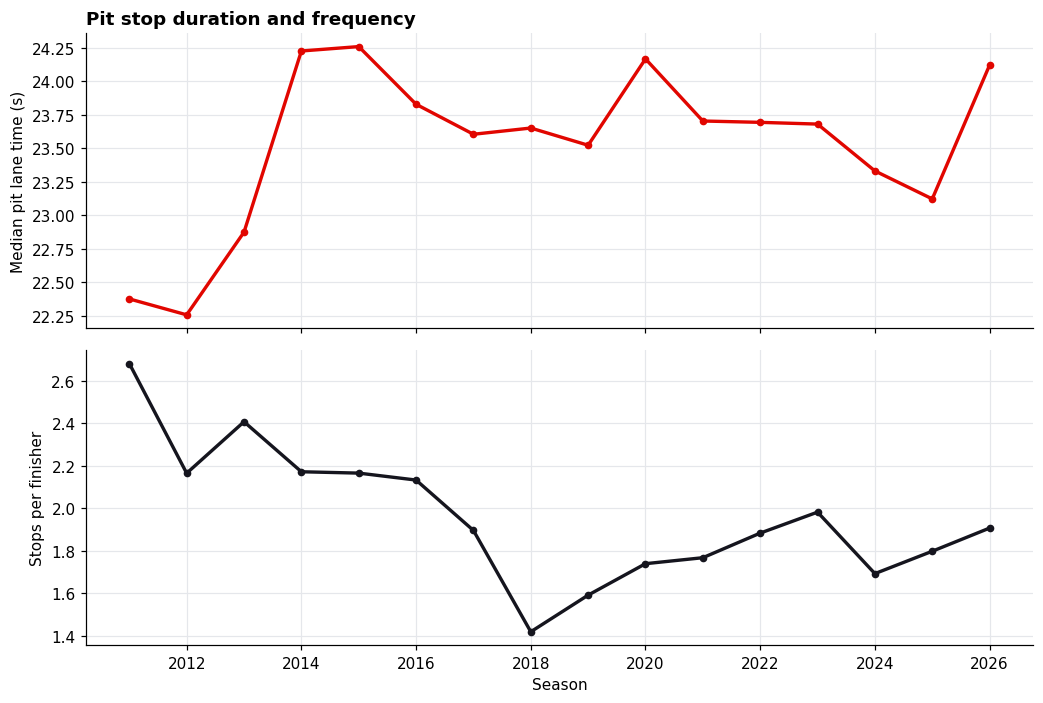

Circuits needing the most stops per finisher (min. 5 races since 2011):


,races,stops
circuit,,
Hockenheimring,5,2.850
Sepang International Circuit,8,2.850
Autódromo José Carlos Pace,15,2.560
Circuit Park Zandvoort,6,2.550
Circuit de Barcelona-Catalunya,16,2.470


In [46]:
ps = C["pit_stops"]; ps = ps[~ps.is_outlier_stop].assign(year=lambda d: d.raceId.map(race_year))
median_stop = ps.groupby("year")["duration_s"].median()
fin = fr[fr.is_finish][["raceId", "driverId"]].drop_duplicates()
pp = perf[perf.has_pit_data].merge(fin, on=["raceId", "driverId"])
stops_per_finisher = pp.groupby(pp.raceId.map(race_year))["n_pit_stops"].mean()

fig, axes = plt.subplots(2, 1, figsize=(9.5, 6.5), sharex=True)
axes[0].plot(median_stop.index, median_stop.values, color=ACCENT, lw=2.2, marker="o", ms=4); axes[0].set_ylabel("Median pit lane time (s)")
axes[0].set_title("Pit stop duration and frequency")
axes[1].plot(stops_per_finisher.index, stops_per_finisher.values, color=INK, lw=2.2, marker="o", ms=4)
axes[1].set_ylabel("Stops per finisher"); axes[1].set_xlabel("Season")
save(fig, "08_pit_stops.png")

by_circuit = pp.assign(circuit=pp.raceId.map(C["races"].set_index("raceId")["circuitId"]).map(circuit_name)).groupby("circuit").agg(
    races=("raceId", "nunique"), stops=("n_pit_stops", "mean")).query("races >= 5").sort_values("stops", ascending=False)
print("Circuits needing the most stops per finisher (min. 5 races since 2011):"); display(by_circuit.head(5).round(2))

## 📌 ملخص الـ Insights

In [47]:
t = d.nlargest(1, "wins").iloc[0]
team_top = w.sum(axis=1).idxmax()
first10, last10 = season[season.index < season.index.min() + 10], season[season.index > season.index.max() - 10]
summary = [
    f"{t['name']} leads with {int(t.wins)} wins and {int(t.podiums)} podiums ({t.win_rate:.1%} win rate).",
    f"{team_name[team_top]} is the most successful constructor with {int(w.sum(axis=1).max())} wins.",
    f"Starting on pole wins {overall.loc[1, 'win']:.1%} of races; P1 is {overall.loc[1, 'win'] / overall.loc[5, 'win']:.1f}x more likely to win than P5.",
    f"Finish rate rose from {first10.finish_rate.mean():.1%} (first ten seasons) to {last10.finish_rate.mean():.1%} (latest ten).",
    f"Highest retirement rate since 2000: {t1.iloc[0]['circuit']} ({t1.iloc[0]['dnf_rate']:.1%}).",
    f"Pole conversion since 2000 ranges from {c.pole_win_rate.min():.0%} to {c.pole_win_rate.max():.0%} depending on the circuit.",
    f"Sprint winners also win the Grand Prix in {same:.0%} of sprint weekends.",
    f"Practice rank correlates {corr['vs_grid'].mean():.2f} with grid position on average (2025+).",
    f"Median pit lane time: {median_stop.iloc[0]:.1f}s in {int(median_stop.index[0])} vs {median_stop.iloc[-1]:.1f}s in {int(median_stop.index[-1])}.",
]
print("\n".join(f"{i}. {s}" for i, s in enumerate(summary, 1)))
(FIG_DIR / "insights_summary.txt").write_text("\n".join(summary), encoding="utf-8")

# تنزيل كل الرسوم (Colab)
import shutil
shutil.make_archive(str(BASE / "f1_figures"), "zip", FIG_DIR)
if IN_COLAB: files.download(str(BASE / "f1_figures.zip"))

1. Lewis Hamilton leads with 106 wins and 209 podiums (26.5% win rate).
2. Ferrari is the most successful constructor with 251 wins.
3. Starting on pole wins 43.3% of races; P1 is 10.2x more likely to win than P5.
4. Finish rate rose from 51.3% (first ten seasons) to 84.0% (latest ten).
5. Highest retirement rate since 2000: Albert Park Grand Prix Circuit (32.4%).
6. Pole conversion since 2000 ranges from 25% to 71% depending on the circuit.
7. Sprint winners also win the Grand Prix in 37% of sprint weekends.
8. Practice rank correlates 0.72 with grid position on average (2025+).
9. Median pit lane time: 22.4s in 2011 vs 24.1s in 2026.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>